In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

print("Current folder:", os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current folder: /Users/kashishvohra/Desktop/Real_Estate_Investment_Advisor

Files available:
['cleaned_housing_prices.csv', 'real_estate_summary.csv', 'india_housing_prices.csv', 'Investment_Prediction.ipynb', 'Real_Estate_Analysis.ipynb', '.ipynb_checkpoints', 'venv']


In [3]:
df = pd.read_csv("cleaned_housing_prices.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,10332.489451,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,8270.727580,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,5046.403075,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,10955.490697,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,3792.245490,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [4]:
print("Columns in dataset:")
print(df.columns.tolist())

print("\nDataset size:")
print(df.shape)

Columns in dataset:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Dataset size:
(250000, 23)


In [5]:
print(df[["Price_in_Lakhs", "Price_per_SqFt"]].describe())

print("\nMissing values:")
print(df.isnull().sum())

       Price_in_Lakhs  Price_per_SqFt
count   250000.000000   250000.000000
mean       254.586854    13058.281776
std        141.349921    13071.850480
min         10.000000      202.247191
25%        132.550000     4802.839710
50%        253.870000     9244.747594
75%        376.880000    15987.388517
max        500.000000    99182.000000

Missing values:
ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                

In [6]:
investment_columns = [
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Public_Transport_Accessibility",
    "Amenities"
]

print(df[[col for col in investment_columns if col in df.columns]].head())

   Price_in_Lakhs  Price_per_SqFt  Age_of_Property  Nearby_Schools  \
0          489.76    10332.489451               35              10   
1          195.52     8270.727580               17               8   
2          183.79     5046.403075               28               9   
3          300.29    10955.490697               34               5   
4          182.90     3792.245490               23               4   

   Nearby_Hospitals Public_Transport_Accessibility  \
0                 3                           High   
1                 1                            Low   
2                 8                            Low   
3                 7                           High   
4                 9                            Low   

                                  Amenities  
0  Playground, Gym, Garden, Pool, Clubhouse  
1  Playground, Clubhouse, Pool, Gym, Garden  
2          Clubhouse, Pool, Playground, Gym  
3  Playground, Clubhouse, Gym, Pool, Garden  
4  Playground, Garden, G

In [7]:
df["Amenities_Count"] = df["Amenities"].fillna("").apply(
    lambda x: len([a for a in x.split(",") if a.strip()])
)

df["Investment_Score"] = (
    (df["Age_of_Property"] <= 15).astype(int)
    + (df["Nearby_Schools"] >= 5).astype(int)
    + (df["Nearby_Hospitals"] >= 5).astype(int)
    + (df["Public_Transport_Accessibility"] == "High").astype(int)
    + (df["Amenities_Count"] >= 3).astype(int)
)

df[["Investment_Score", "Amenities_Count"]].head()

,Investment_Score,Amenities_Count
0,3,5
1,2,5
2,3,4
3,4,5
4,2,5


In [8]:
df["Good_Investment"] = (
    df["Investment_Score"] >= 3
).astype(int)

print("Investment classification counts:")
print(df["Good_Investment"].value_counts())

print("\nPercentages:")
print(df["Good_Investment"].value_counts(normalize=True) * 100)

Investment classification counts:
Good_Investment
1    129735
0    120265
Name: count, dtype: int64

Percentages:
Good_Investment
1    51.894
0    48.106
Name: proportion, dtype: float64


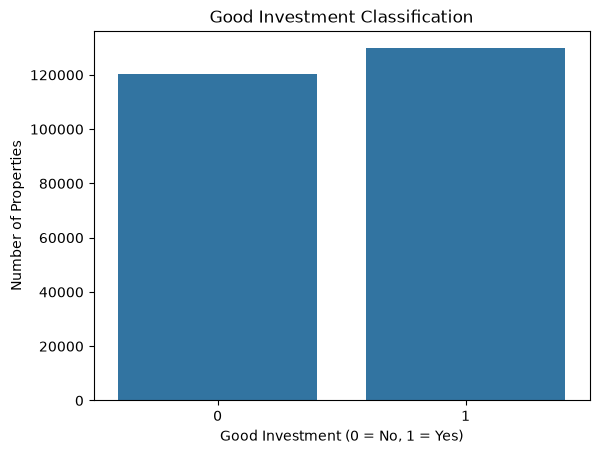

In [9]:
sns.countplot(data=df, x="Good_Investment")

plt.title("Good Investment Classification")
plt.xlabel("Good Investment (0 = No, 1 = Yes)")
plt.ylabel("Number of Properties")

plt.show()

In [10]:
features = [
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Public_Transport_Accessibility",
    "Amenities_Count"
]

X = pd.get_dummies(df[features], columns=[
    "Public_Transport_Accessibility"
], dtype=int)

y = df["Good_Investment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (200000, 7)
Testing data: (50000, 7)


In [11]:
rf_classifier = RandomForestClassifier(
    n_estimators=50,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf_classifier.fit(X_train, y_train)

print("Classification model trained successfully!")

Classification model trained successfully!


In [12]:
y_pred = rf_classifier.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24053
           1       1.00      1.00      1.00     25947

    accuracy                           1.00     50000
   macro avg       1.00      1.00      1.00     50000
weighted avg       1.00      1.00      1.00     50000


Confusion Matrix:
[[24053     0]
 [    0 25947]]


In [13]:
import joblib

joblib.dump(rf_classifier, "investment_classifier.pkl")
joblib.dump(X.columns.tolist(), "investment_features.pkl")

print("Model and features saved successfully!")

Model and features saved successfully!


In [14]:
df.to_csv("investment_dataset.csv", index=False)

print("Investment dataset saved successfully!")

Investment dataset saved successfully!


In [15]:
import os

files = [
    "investment_classifier.pkl",
    "investment_features.pkl",
    "investment_dataset.csv"
]

for file in files:
    print(file, ":", "Saved" if os.path.exists(file) else "Missing")

investment_classifier.pkl : Saved
investment_features.pkl : Saved
investment_dataset.csv : Saved


In [16]:
annual_growth_rate = 0.05

print("Assumed annual growth rate:", annual_growth_rate * 100, "%")

Assumed annual growth rate: 5.0 %


In [17]:
df["Estimated_Price_5_Years"] = (
    df["Price_in_Lakhs"] * (1 + annual_growth_rate) ** 5
)

print("Five-year price estimates calculated!")

df[[
    "City",
    "Price_in_Lakhs",
    "Estimated_Price_5_Years"
]].head()

Five-year price estimates calculated!


,City,Price_in_Lakhs,Estimated_Price_5_Years
0,Chennai,489.76,625.071658
1,Pune,195.52,249.538571
2,Ludhiana,183.79,234.567788
3,Jodhpur,300.29,383.254590
4,Jaipur,182.90,233.431898


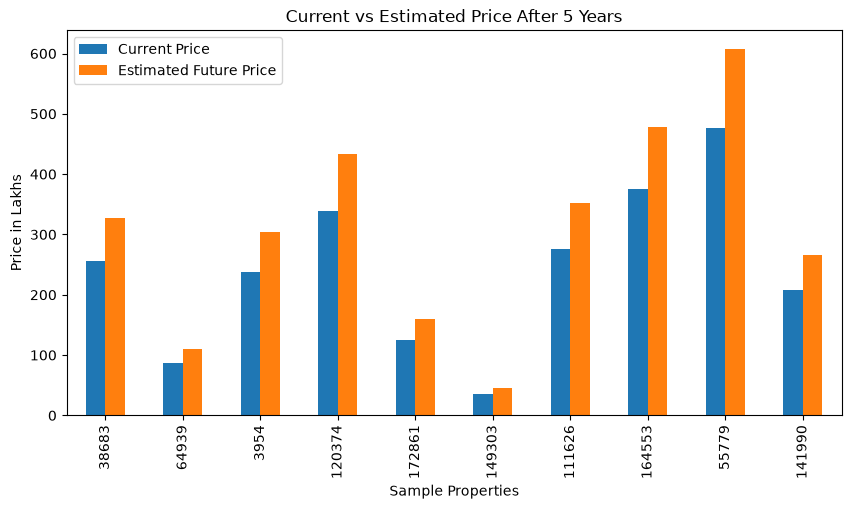

In [18]:
sample = df.sample(10, random_state=42)

sample[[
    "Price_in_Lakhs",
    "Estimated_Price_5_Years"
]].plot(kind="bar", figsize=(10, 5))

plt.title("Current vs Estimated Price After 5 Years")
plt.xlabel("Sample Properties")
plt.ylabel("Price in Lakhs")
plt.legend(["Current Price", "Estimated Future Price"])
plt.show()

In [19]:
df.to_csv("investment_dataset.csv", index=False)

print("Five-year estimates saved successfully!")

Five-year estimates saved successfully!


In [20]:
import importlib.util

if importlib.util.find_spec("mlflow"):
    print("MLflow is already installed!")
else:
    print("MLflow needs to be installed.")

MLflow needs to be installed.


In [21]:
%pip install mlflow

  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 26.4 MB/s  0:00:008.4 MB/s eta 0:00:0101
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 29.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 23.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.9/548.9 kB 13.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 32.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 27.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.9/35.9 MB 4.6 MB/s  0:00:07 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 4.0 MB/s  0:00:003.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 9.0 MB/s  0:00:009.1 MB/s eta 0:00:01
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)
  Attempting uninstall: certifi━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━ 19/55 [graphql-core]
    Found existing installation: certi

In [22]:
import importlib.util

if importlib.util.find_spec("mlflow"):
    print("MLflow is already installed!")
else:
    print("MLflow needs to be installed.")

MLflow is already installed!


In [23]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Real_Estate_Investment")

print("MLflow setup completed!")

2026/11/02 20:43:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/02 20:43:32 INFO mlflow.store.db.utils: Updating database tables
2026/11/02 20:43:32 INFO mlflow.tracking.fluent: Experiment with name 'Real_Estate_Investment' does not exist. Creating a new experiment.


MLflow setup completed!


In [25]:
with mlflow.start_run(run_name="Random_Forest_Investment_Fixed"):

    mlflow.log_params({
        "model": "RandomForestClassifier",
        "n_estimators": 50,
        "max_depth": 8
    })

    mlflow.log_metric(
        "accuracy",
        accuracy_score(y_test, y_pred)
    )

print("MLflow experiment recorded successfully!")

MLflow experiment recorded successfully!


In [26]:
runs = mlflow.search_runs(
    experiment_names=["Real_Estate_Investment"]
)

print(runs[[
    "tags.mlflow.runName",
    "metrics.accuracy",
    "status"
]].head())

              tags.mlflow.runName  metrics.accuracy    status
0  Random_Forest_Investment_Fixed               1.0  FINISHED
1        Random_Forest_Investment               1.0    FAILED


In [27]:
import os

print(
    "Classification model:",
    "Saved" if os.path.exists("investment_classifier.pkl")
    else "Missing"
)

Classification model: Saved


In [28]:
import importlib.util

if importlib.util.find_spec("streamlit"):
    print("Streamlit is already installed!")
else:
    print("Streamlit needs to be installed.")

Streamlit needs to be installed.


In [29]:
%pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 50.1 MB/s  0:00:00.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 35.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 17.1 MB/s  0:00:00 17.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [streamlit]━ 4/5 [streamlit]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /Library/Frameworks/Python.framework/Versions/3.14/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
import streamlit as st

print("Streamlit version:", st.__version__)
print("Streamlit is ready!")

Streamlit version: 1.66.1
Streamlit is ready!


In [31]:
app_code = '''
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="Real Estate Investment Advisor", layout="wide")

st.title("🏠 Real Estate Investment Advisor")
st.write("Explore properties and estimate investment suitability.")

df = pd.read_csv("investment_dataset.csv")

st.subheader("Property Market Overview")

col1, col2, col3 = st.columns(3)

col1.metric("Total Properties", f"{len(df):,}")
col2.metric("Average Price (Lakhs)", f"₹{df['Price_in_Lakhs'].mean():.2f}")
col3.metric("Cities", df["City"].nunique())

st.subheader("Explore Properties")

city = st.selectbox("Select City", ["All"] + sorted(df["City"].unique().tolist()))

filtered_df = df if city == "All" else df[df["City"] == city]

st.dataframe(
    filtered_df[["City", "Locality", "Property_Type", "BHK",
                 "Size_in_SqFt", "Price_in_Lakhs"]].head(100),
    use_container_width=True
)
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [32]:
import os

print("App file exists:", os.path.exists("app.py"))
print("File size:", os.path.getsize("app.py"), "bytes")

App file exists: True
File size: 899 bytes


In [33]:
print("Files needed for the app:")

for filename in [
    "app.py",
    "investment_dataset.csv",
    "investment_classifier.pkl",
    "investment_features.pkl"
]:
    print(filename, ":", "Found" if os.path.exists(filename) else "Missing")

Files needed for the app:
app.py : Found
investment_dataset.csv : Found
investment_classifier.pkl : Found
investment_features.pkl : Found


In [34]:
extra_code = '''
st.subheader("Investment Suitability Prediction")

age = st.number_input("Property Age (Years)", 0, 100, 10)
schools = st.number_input("Nearby Schools", 0, 50, 5)
hospitals = st.number_input("Nearby Hospitals", 0, 50, 5)
transport = st.selectbox(
    "Public Transport Accessibility",
    ["High", "Medium", "Low"]
)
amenities = st.number_input("Number of Amenities", 0, 20, 3)

if st.button("Check Investment Suitability"):
    model = joblib.load("investment_classifier.pkl")
    features = joblib.load("investment_features.pkl")

    input_data = pd.DataFrame([{
        "Age_of_Property": age,
        "Nearby_Schools": schools,
        "Nearby_Hospitals": hospitals,
        "Amenities_Count": amenities,
        "Public_Transport_Accessibility_High": int(transport == "High"),
        "Public_Transport_Accessibility_Low": int(transport == "Low"),
        "Public_Transport_Accessibility_Medium": int(transport == "Medium")
    }])

    input_data = input_data.reindex(columns=features, fill_value=0)
    prediction = model.predict(input_data)[0]

    if prediction == 1:
        st.success("Good Investment Suitability")
    else:
        st.warning("Lower Investment Suitability")

    st.caption("Based on a rule-based suitability score, not actual investment returns.")
'''

with open("app.py", "a") as f:
    f.write("\n" + extra_code)

print("Investment prediction form added!")

Investment prediction form added!


In [35]:
price_code = '''
st.subheader("Five-Year Property Price Estimate")

current_price = st.number_input(
    "Current Property Price (₹ Lakhs)",
    min_value=1.0,
    value=100.0
)

growth_rate = st.slider(
    "Assumed Annual Appreciation (%)",
    min_value=0,
    max_value=15,
    value=5
)

future_price = current_price * (1 + growth_rate / 100) ** 5

if st.button("Calculate Future Price"):
    st.metric("Estimated Price After 5 Years", f"₹{future_price:.2f} Lakhs")
    st.caption("Illustrative scenario only; future market prices are uncertain.")
'''

with open("app.py", "a") as f:
    f.write("\n" + price_code)

print("Five-year price estimation added!")

Five-year price estimation added!


In [36]:
import ast

with open("app.py", "r") as f:
    code = f.read()

ast.parse(code)

print("App code syntax is valid!")
print("Total lines:", len(code.splitlines()))

App code syntax is valid!
Total lines: 89


In [37]:
filter_code = '''
st.subheader("Filter Properties by Budget and BHK")

max_price = st.slider(
    "Maximum Budget (₹ Lakhs)",
    10, 500, 250
)

bhk = st.selectbox(
    "Select BHK",
    ["All"] + sorted(df["BHK"].unique().tolist())
)

filtered = filtered_df[
    filtered_df["Price_in_Lakhs"] <= max_price
]

if bhk != "All":
    filtered = filtered[filtered["BHK"] == bhk]

st.write("Matching Properties:", len(filtered))

st.dataframe(
    filtered[["City", "Locality", "BHK",
              "Size_in_SqFt", "Price_in_Lakhs"]].head(100)
)
'''

with open("app.py", "a") as f:
    f.write("\n" + filter_code)

print("Property filters added successfully!")

Property filters added successfully!


In [38]:
chart_code = '''
st.subheader("Property Market Insights")

avg_prices = (
    df.groupby("City")["Price_in_Lakhs"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

st.write("Top 10 Cities by Average Property Price")
st.bar_chart(avg_prices)

st.write("Property Type Distribution")
st.bar_chart(df["Property_Type"].value_counts())
'''

with open("app.py", "a") as f:
    f.write("\n" + chart_code)

print("Market insight charts added successfully!")

Market insight charts added successfully!


In [39]:
import ast

with open("app.py", "r") as f:
    code = f.read()

ast.parse(code)

print("Updated app code is valid!")

Updated app code is valid!


In [40]:
requirements = """streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
mlflow
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [41]:
documentation = """# Real Estate Investment Advisor

## Project Objective
Analyze real estate data and build an interactive
application to explore property investment suitability.

## Dataset
250,000 properties across 42 Indian cities.

## Tools Used
Python, Pandas, Scikit-learn, MLflow and Streamlit.

## Features
- Property market overview
- City, budget and BHK filters
- Investment suitability classification
- Five-year price scenario estimation
- Property market visualizations

## Important Limitations
Investment suitability is based on defined scoring rules,
not observed investment returns.

The five-year estimate uses an assumed annual growth rate,
not a machine-learning forecast trained on historical prices.

## How to Run
Install dependencies:
pip install -r requirements.txt

Start the application:
streamlit run app.py
"""

with open("PROJECT_DOCUMENTATION.md", "w") as f:
    f.write(documentation)

print("Project documentation created!")

Project documentation created!


In [42]:
import os

project_files = [
    "Real_Estate_Analysis.ipynb",
    "Investment_Prediction.ipynb",
    "app.py",
    "requirements.txt",
    "PROJECT_DOCUMENTATION.md",
    "investment_dataset.csv",
    "investment_classifier.pkl",
    "investment_features.pkl"
]

for file in project_files:
    print(file, ":", "Found" if os.path.exists(file) else "Missing")

Real_Estate_Analysis.ipynb : Found
Investment_Prediction.ipynb : Found
app.py : Found
requirements.txt : Found
PROJECT_DOCUMENTATION.md : Found
investment_dataset.csv : Found
investment_classifier.pkl : Found
investment_features.pkl : Found


In [43]:
import os

for file in project_files:
    size_mb = os.path.getsize(file) / (1024 * 1024)
    print(f"{file}: {size_mb:.2f} MB")

Real_Estate_Analysis.ipynb: 1.89 MB
Investment_Prediction.ipynb: 0.13 MB
app.py: 0.00 MB
requirements.txt: 0.00 MB
PROJECT_DOCUMENTATION.md: 0.00 MB
investment_dataset.csv: 48.21 MB
investment_classifier.pkl: 0.61 MB
investment_features.pkl: 0.00 MB


In [44]:
import ast

with open("app.py", "r") as f:
    ast.parse(f.read())

print("Streamlit app syntax: Valid")

Streamlit app syntax: Valid
